In [1]:
pip install timm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 119.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 90.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 103.9 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitl

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import transforms, datasets
import matplotlib.pyplot as plt
from tqdm import tqdm
import timm

from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix,
    cohen_kappa_score,
    accuracy_score,
    roc_curve,
    roc_auc_score,
    auc
)
import numpy as np
import pandas as pd


/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)


Using: cuda


In [4]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])


In [5]:
dataset = datasets.ImageFolder("/kaggle/input/with-attetion")

train_size = int(0.7 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_ds, val_ds, test_ds = random_split(dataset, [train_size, val_size, test_size])

train_ds.dataset.transform = train_transform
val_ds.dataset.transform = test_transform
test_ds.dataset.transform = test_transform

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=8, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=8, num_workers=2)

classes = dataset.classes
num_classes = len(classes)
print("Classes:", classes)


Classes: ['advanced_glaucoma', 'early_glaucoma', 'normal_control']


In [6]:
model = timm.create_model(
    "davit_base.msft_in1k", 
    pretrained=True,
    num_classes=num_classes
).to(device)


model.safetensors:   0%|          | 0.00/352M [00:00<?, ?B/s]

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)


In [8]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0

    pbar = tqdm(loader, desc="Training", leave=False)
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        pbar.set_postfix(loss=loss.item())

    return total_loss / len(loader)


def validate(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = total = 0

    pbar = tqdm(loader, desc="Validating", leave=False)
    with torch.no_grad():
        for imgs, labels in pbar:
            imgs, labels = imgs.to(device), labels.to(device)

            outputs = model(imgs)
            loss = criterion(outputs, labels)
            preds = outputs.argmax(dim=1)

            total_loss += loss.item()
            correct += (preds == labels).sum().item()
            total += labels.size(0)

            pbar.set_postfix(loss=loss.item())

    return total_loss / len(loader), correct / total


In [9]:
from tqdm import tqdm
import torch

EPOCHS = 30
best_val_acc = 0

train_losses, val_losses, val_accs = [], [], []

SAVE_PATH = "/kaggle/working/best_davit_model.pth"

for epoch in range(EPOCHS):
    print(f"\n===== Epoch {epoch+1}/{EPOCHS} =====")

    # ---- Training ----
    model.train()
    running_loss = 0.0

    for imgs, labels in tqdm(train_loader, desc=f"Training {epoch+1}", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    # ---- Validation ----
    model.eval()
    val_running_loss = 0.0
    correct, total = 0, 0
    
    with torch.no_grad():
        for imgs, labels in tqdm(val_loader, desc=f"Validating {epoch+1}", leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(dim=1)

            loss = criterion(outputs, labels)
            val_running_loss += loss.item()

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_loss = val_running_loss / len(val_loader)
    val_acc = correct / total

    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss  : {val_loss:.4f}")
    print(f"Val Acc   : {val_acc:.4f}")

    # ---- Save best model ----
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), SAVE_PATH)
        print(f"🔥 Best model updated! Saved at: {SAVE_PATH}")

print("\n🎯 Training Completed!")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")



===== Epoch 1/30 =====


Train Loss: 0.5558
Val Loss  : 0.5896
Val Acc   : 0.7273
🔥 Best model updated! Saved at: /kaggle/working/best_davit_model.pth

===== Epoch 2/30 =====


Train Loss: 0.3889
Val Loss  : 0.4107
Val Acc   : 0.8571
🔥 Best model updated! Saved at: /kaggle/working/best_davit_model.pth

===== Epoch 3/30 =====


Train Loss: 0.2685
Val Loss  : 0.3461
Val Acc   : 0.8701
🔥 Best model updated! Saved at: /kaggle/working/best_davit_model.pth

===== Epoch 4/30 =====


Train Loss: 0.1296
Val Loss  : 0.4213
Val Acc   : 0.8528

===== Epoch 5/30 =====


Train Loss: 0.0662
Val Loss  : 0.5188
Val Acc   : 0.8225

===== Epoch 6/30 =====


... (21 outputs left out)

Train Loss: 0.0018
Val Loss  : 0.8897
Val Acc   : 0.8485

===== Epoch 28/30 =====


Train Loss: 0.0018
Val Loss  : 0.9017
Val Acc   : 0.8485

===== Epoch 29/30 =====


Train Loss: 0.0017
Val Loss  : 0.9048
Val Acc   : 0.8571

===== Epoch 30/30 =====


Train Loss: 0.0015
Val Loss  : 0.9202
Val Acc   : 0.8485

🎯 Training Completed!
Best Validation Accuracy: 0.8745


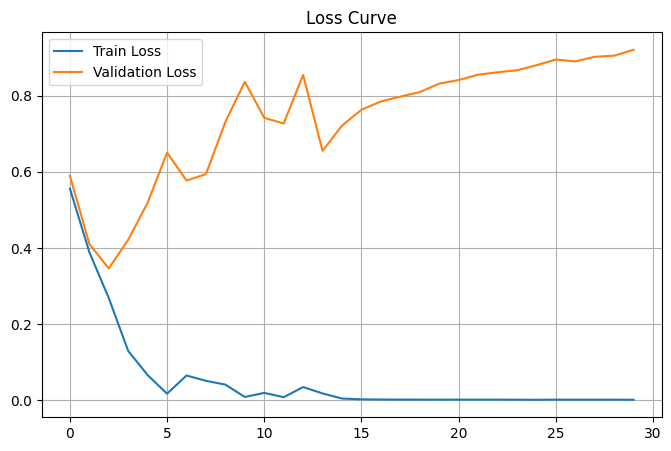

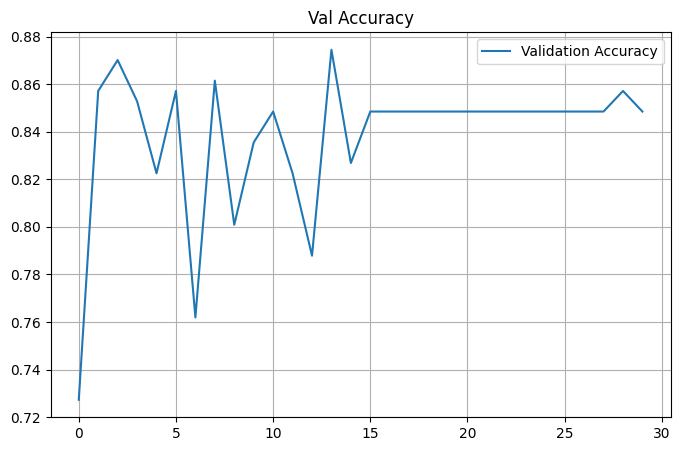

In [10]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.legend(); plt.grid(); plt.title("Loss Curve"); plt.show()

plt.figure(figsize=(8,5))
plt.plot(val_accs, label="Validation Accuracy")
plt.legend(); plt.grid(); plt.title("Val Accuracy"); plt.show()


In [11]:
model.load_state_dict(torch.load("best_davit_model.pth"))
model.eval()

all_labels = []
all_preds = []
all_probs  = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)

        preds = probs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)


In [12]:
accuracy = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="weighted"
)
kappa = cohen_kappa_score(all_labels, all_preds)

print("\n===== TEST METRICS =====")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)
print("Kappa    :", kappa)



===== TEST METRICS =====
Accuracy : 0.8540772532188842
Precision: 0.8547819832510458
Recall   : 0.8540772532188842
F1-score : 0.852777413603745
Kappa    : 0.7653436018957346


AUC (Macro): 0.9451833789515872
AUC (Weighted): 0.958061642103223


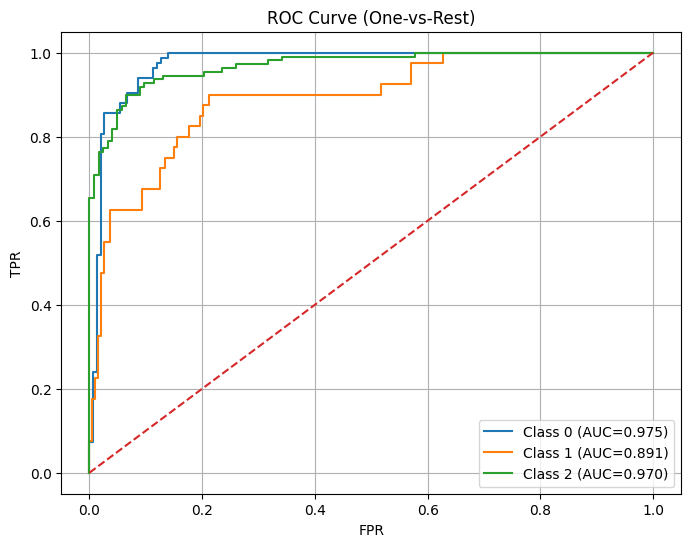

In [13]:
labels_onehot = np.zeros((len(all_labels), num_classes))
labels_onehot[np.arange(len(all_labels)), all_labels] = 1

auc_macro = roc_auc_score(labels_onehot, all_probs, average="macro", multi_class="ovr")
auc_weighted = roc_auc_score(labels_onehot, all_probs, average="weighted", multi_class="ovr")

print("AUC (Macro):", auc_macro)
print("AUC (Weighted):", auc_weighted)

plt.figure(figsize=(8,6))
for c in range(num_classes):
    fpr, tpr, _ = roc_curve(labels_onehot[:, c], all_probs[:, c])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Class {c} (AUC={class_auc:.3f})")

plt.plot([0,1],[0,1],'--')
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROC Curve (One-vs-Rest)")
plt.legend(); plt.grid()
plt.show()


In [14]:
import os
print(os.getcwd())


/kaggle/working


In [15]:
import os

print("Files in /kaggle/working/:")
print(os.listdir("/kaggle/working"))


Files in /kaggle/working/:
['best_davit_model.pth', '__notebook__.ipynb']
